# Customer Churn Prediction: Experimental Study

**Research focus:** Class imbalance handling and decision-threshold optimization  
**Dataset:** IBM Telco Customer Churn (`Telco-Customer-Churn.csv`)  
**Task:** Binary classification — predict whether a customer churns.

## 1. Problem statement

Customer churn is a challenge for subscription-based businesses because losing customers can reduce recurring revenue and increase replacement-acquisition costs. Customer records contain information such as tenure, monthly charges, contract type, payment method, and subscribed services that may help identify customers who are more likely to leave.

A churn model can still be inadequate even when its overall accuracy appears reasonable: it may miss customers who actually churn, particularly when churn cases are less common than retained customers. The usefulness of a model also depends on the classification threshold used to turn predicted probabilities into churn / non-churn labels.

This project will compare selected machine-learning models and investigate how class weighting and decision-threshold selection affect churn detection. Models will be assessed with consistent metrics, using validation data for model/threshold selection and a held-out test set for final evaluation.

## 2. Motivation

The practical motivation is to help a business prioritize retention outreach by identifying customers who may be at risk of leaving. From a research perspective, the project investigates why accuracy alone is not enough and measures the trade-off between finding more churners (recall) and avoiding unnecessary alerts (precision).

The work also demonstrates an end-to-end research workflow: literature review, data inspection, preprocessing, controlled experiments, quantitative evaluation, interpretation, and limitations.

## 3. Research questions and hypotheses

**RQ1.** How do selected classification models compare on the same churn dataset?  
**RQ2.** Does class weighting change churn-class recall, precision, and F1-score?  
**RQ3.** How does the decision threshold affect the precision–recall trade-off?  
**RQ4.** Is the model with the highest accuracy also the best at identifying churners?

**H1.** Class weighting changes churn-class performance compared with an untreated baseline.  
**H2.** Changing the classification threshold changes precision and recall.  
**H3.** The model with the highest accuracy may differ from the model preferred for churn detection.

These are hypotheses to test, not conclusions to assume.

## 4. Research methodology

This project uses:
- **Literature-based research:** review prior work on churn prediction, class imbalance, and threshold selection.
- **Quantitative research:** measure accuracy, precision, recall, F1, ROC-AUC, and PR-AUC.
- **Empirical research:** draw conclusions from the observed dataset and model results.
- **Experimental research:** change model/imbalance/threshold settings in a controlled way.
- **Comparative research:** compare several algorithms under a consistent evaluation protocol.
- **Applied research:** investigate a real business prediction problem.

### Experimental plan
1. Inspect and clean the data.
2. Create stratified train, validation, and test partitions.
3. Compare Logistic Regression, Decision Tree, Random Forest, and a multilayer perceptron (neural-network classifier).
4. Compare selected class-weighted models with their baseline versions.
5. Select a decision threshold using validation data only.
6. Evaluate the selected configuration once on the untouched test set.

## 5. Imports and reproducibility

The notebook uses scikit-learn models so the main experiments do not require TensorFlow. A `MLPClassifier` provides a neural-network comparison model. Set the random seed to make splits and supported model training reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

## 6. Load the dataset

Place `Telco-Customer-Churn.csv` in the same folder as this notebook, or update `DATA_PATH` to the correct location.

In [2]:
DATA_PATH = "Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 7. Initial data inspection

Check column types, missing values, duplicate rows, and the target distribution before preprocessing.

In [3]:
display(df.info())
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())
print("\nChurn counts:")
display(df["Churn"].value_counts(dropna=False).to_frame("count"))
print("\nChurn proportions:")
display((df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

,missing_values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0

Churn counts:


,count
Churn,
No,5174
Yes,1869



Churn proportions:


,percent
Churn,
No,73.46
Yes,26.54


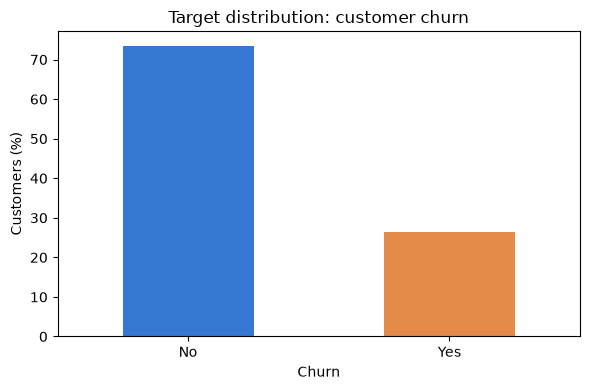

In [4]:
ax = (df["Churn"].value_counts(normalize=True) * 100).reindex(["No", "Yes"]).plot(
    kind="bar", figsize=(6, 4), color=["#3478D4", "#E58B4A"]
)
ax.set_title("Target distribution: customer churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Customers (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 8. Data cleaning and exploratory analysis

`TotalCharges` can contain blank strings, so convert it to numeric and let invalid values become missing values. The preprocessing pipeline below imputes missing numeric values using training data only. The customer identifier is removed because it is not a meaningful behavioral predictor.

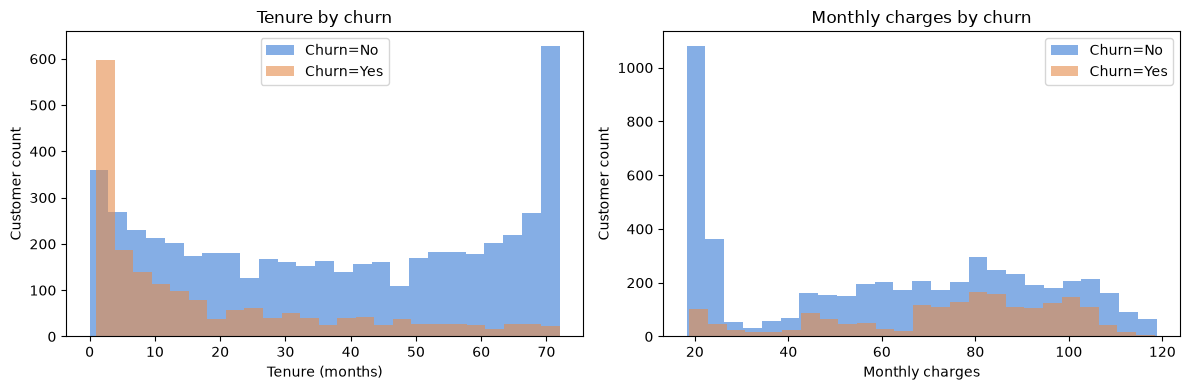

In [5]:
df = df.copy()

# Convert blank or invalid TotalCharges values to NaN
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove duplicate records if any exist
df = df.drop_duplicates().reset_index(drop=True)

# Target must be present and should contain Yes / No
df = df.dropna(subset=["Churn"])
df = df[df["Churn"].isin(["Yes", "No"])].copy()

# Explore tenure and monthly charges by churn class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color in [("No", "#3478D4"), ("Yes", "#E58B4A")]:
    subset = df.loc[df["Churn"] == label]
    axes[0].hist(subset["tenure"].dropna(), bins=25, alpha=0.6, label=f"Churn={label}", color=color)
    axes[1].hist(subset["MonthlyCharges"].dropna(), bins=25, alpha=0.6, label=f"Churn={label}", color=color)

axes[0].set_title("Tenure by churn")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Customer count")
axes[1].set_title("Monthly charges by churn")
axes[1].set_xlabel("Monthly charges")
axes[1].set_ylabel("Customer count")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## Define features and target 

Encode the target as `1 = churn` and `0 = no churn`. Split the data before fitting preprocessing transformations to avoid data leakage. The identifier is removed if present.

data leaking: using whole dataset might influence the test dataset leading it towards overfitting problem


In [6]:
data = df.drop(columns=["customerID"], errors="ignore").copy()
y = data["Churn"].map({"No": 0, "Yes": 1}).astype(int)
X = data.drop(columns=["Churn"])

# 60% train, 20% validation, 20% test; stratify preserves class proportions
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train: {X_train.shape}, Validation: {X_valid.shape}, Test: {X_test.shape}")
print("Train churn rate:", round(y_train.mean(), 3))
print("Validation churn rate:", round(y_valid.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))
#equal churn rates across splits indicates that stratification worked as intended

Train: (4225, 19), Validation: (1409, 19), Test: (1409, 19)
Train churn rate: 0.265
Validation churn rate: 0.265
Test churn rate: 0.265


## 10. Preprocessing pipeline

Numeric columns are imputed and scaled; categorical columns are imputed and one-hot encoded. Since the pipeline is fitted separately within each model on the training split, validation/test information is not used to learn preprocessing parameters.

In [7]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15


## 11. Experiment 1 — Compare baseline models

The models use the same train/validation split and preprocessing. The validation set is used for comparison; the test set is not used for model selection.

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=10),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, min_samples_leaf=2, n_jobs=-1
    ),
    "Neural Network (MLP)": MLPClassifier(
        hidden_layer_sizes=(64, 32), max_iter=400, early_stopping=True,
        random_state=RANDOM_STATE
    )
}

#MPL works same as tensorflow and pytorch, but is simpler to use for small datasets. 
# It is a feedforward neural network that can be used for classification and regression tasks.
# 2 hidden layer with 64 and 32 neurons

baseline_pipelines = {}
baseline_rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    valid_prob = pipe.predict_proba(X_valid)[:, 1]
    valid_pred = (valid_prob >= 0.5).astype(int)

    baseline_pipelines[name] = pipe
    baseline_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, valid_pred),
        "Churn precision": precision_score(y_valid, valid_pred, zero_division=0),
        "Churn recall": recall_score(y_valid, valid_pred, zero_division=0),
        "Churn F1": f1_score(y_valid, valid_pred, zero_division=0),
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("Churn F1", ascending=False)
display(baseline_results.round(3))

,Model,Accuracy,Churn precision,Churn recall,Churn F1
0,Logistic Regression,0.823,0.696,0.588,0.638
3,Neural Network (MLP),0.804,0.648,0.572,0.608
2,Random Forest,0.805,0.677,0.505,0.579
1,Decision Tree,0.779,0.597,0.519,0.555


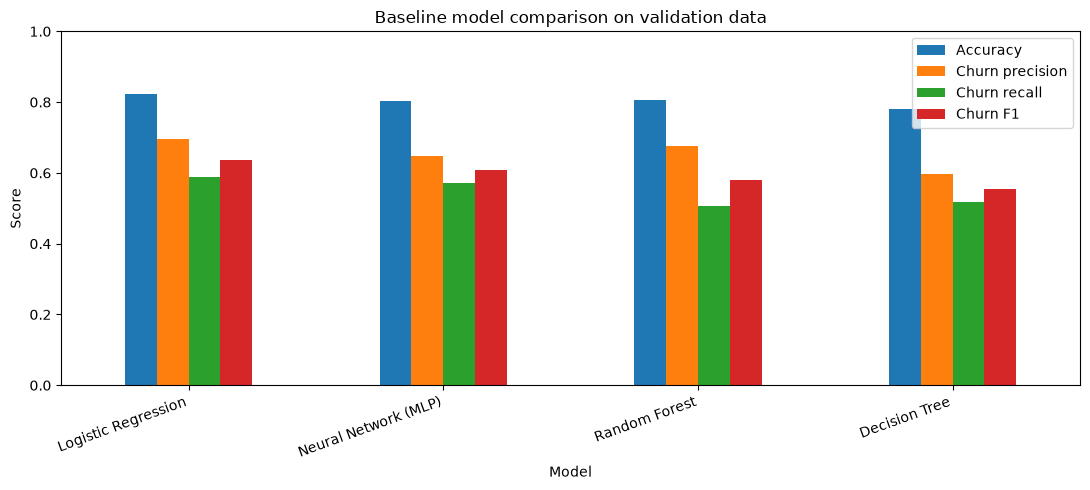

In [9]:
baseline_results.set_index("Model")[["Accuracy", "Churn precision", "Churn recall", "Churn F1"]].plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Baseline model comparison on validation data")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**interpretation**

##### highest validation F1: Logistic Regression
##### highest recall: Logistic Regression
##### Are these the same model?: Yes

## 12. Experiment 2 — Class-imbalance handling

Compare baseline models with class-weighted versions. Class weighting penalizes errors on the minority class more strongly during training. This is an experiment: it may improve recall, but it can also reduce precision or overall accuracy.

The following comparison uses Logistic Regression and Random Forest as representative models.

In [10]:
weighted_models = {
    "Logistic Regression (balanced)": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE,
        min_samples_leaf=2, n_jobs=-1
    )
}

imbalance_rows = []
imbalance_pipelines = {}

for name, estimator in weighted_models.items():
    pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    valid_prob = pipe.predict_proba(X_valid)[:, 1]
    valid_pred = (valid_prob >= 0.5).astype(int)
    imbalance_pipelines[name] = pipe

    imbalance_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, valid_pred),
        "Churn precision": precision_score(y_valid, valid_pred, zero_division=0),
        "Churn recall": recall_score(y_valid, valid_pred, zero_division=0),
        "Churn F1": f1_score(y_valid, valid_pred, zero_division=0),
    })

imbalance_results = pd.DataFrame(imbalance_rows).sort_values("Churn F1", ascending=False)
display(imbalance_results.round(3))

,Model,Accuracy,Churn precision,Churn recall,Churn F1
0,Logistic Regression (balanced),0.750,0.519,0.821,0.636
1,Random Forest (balanced),0.779,0.566,0.714,0.631


## 13. Select a candidate using validation data

Using validation F1 as the default candidate-selection metric, while also reviewing recall and precision. 

F1 is harmonic mean of precision and recall

In [11]:
candidate_pipelines = {**baseline_pipelines, **imbalance_pipelines}

selection_rows = []
for name, pipe in candidate_pipelines.items():
    prob = pipe.predict_proba(X_valid)[:, 1]
    pred = (prob >= 0.5).astype(int)
    selection_rows.append({
        "Model": name,
        "Validation F1": f1_score(y_valid, pred, zero_division=0),
        "Validation recall": recall_score(y_valid, pred, zero_division=0),
        "Validation precision": precision_score(y_valid, pred, zero_division=0)
    })

selection_table = pd.DataFrame(selection_rows).sort_values("Validation F1", ascending=False)
display(selection_table.round(3))

best_model_name = selection_table.iloc[0]["Model"]
best_model = candidate_pipelines[best_model_name]
print("Candidate selected using validation F1:", best_model_name)

,Model,Validation F1,Validation recall,Validation precision
0,Logistic Regression,0.638,0.588,0.696
4,Logistic Regression (balanced),0.636,0.821,0.519
5,Random Forest (balanced),0.631,0.714,0.566
3,Neural Network (MLP),0.608,0.572,0.648
2,Random Forest,0.579,0.505,0.677
1,Decision Tree,0.555,0.519,0.597


Candidate selected using validation F1: Logistic Regression


## 14. Experiment 3 — Decision-threshold optimization

A model outputs a probability. The threshold determines when a probability is converted into a churn label. Choose the threshold using validation data only. Here, the threshold with the highest validation F1 is selected from a pre-defined grid. If several thresholds tie, the first maximum in the grid is selected.

,Threshold,Precision,Recall,F1,Accuracy
0,0.20,0.469,0.888,0.614,0.703
1,0.25,0.509,0.837,0.633,0.742
2,0.30,0.540,0.791,0.642,0.766
3,0.35,0.570,0.730,0.640,0.782
4,0.40,0.598,0.701,0.645,0.796
5,0.45,0.638,0.636,0.637,0.808
6,0.50,0.696,0.588,0.638,0.823
7,0.55,0.724,0.497,0.590,0.816
8,0.60,0.746,0.401,0.522,0.805
9,0.65,0.763,0.283,0.413,0.786


Selected threshold from validation data: 0.4


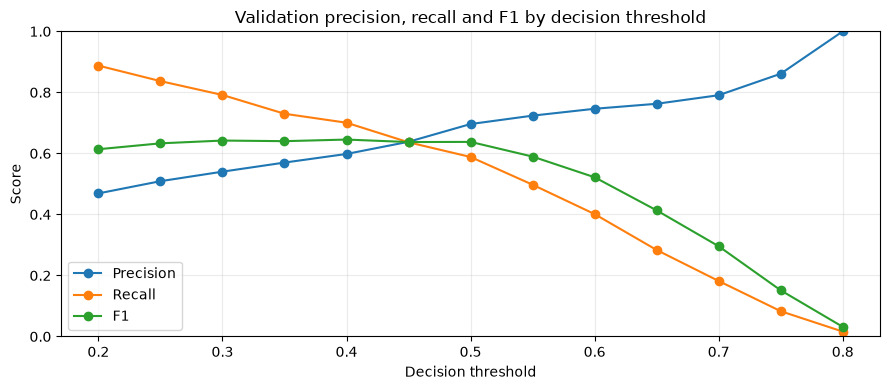

In [12]:
valid_prob = best_model.predict_proba(X_valid)[:, 1]
thresholds = np.arange(0.20, 0.81, 0.05)

threshold_rows = []
for threshold in thresholds:
    pred = (valid_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "Accuracy": accuracy_score(y_valid, pred)
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

best_threshold = float(
    threshold_results.loc[threshold_results["F1"].idxmax(), "Threshold"]
)
print("Selected threshold from validation data:", best_threshold)

threshold_results.set_index("Threshold")[["Precision", "Recall", "F1"]].plot(
    marker="o", figsize=(9, 4)
)
plt.title("Validation precision, recall and F1 by decision threshold")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 15. Experiment 4 — Final evaluation on the test set

This is the final, held-out evaluation. Do not change the model or threshold after inspecting these test results. If you make further changes, you need a new independent test set or a clearly disclosed evaluation protocol.

In [13]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("Selected model:", best_model_name)
print("Selected threshold:", best_threshold)
print("\nClassification report:")
print(classification_report(
    y_test, test_pred, labels=[0, 1],
    target_names=["No churn", "Churn"], zero_division=0
))

final_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, test_pred),
    "Churn precision": precision_score(y_test, test_pred, zero_division=0),
    "Churn recall": recall_score(y_test, test_pred, zero_division=0),
    "Churn F1": f1_score(y_test, test_pred, zero_division=0),
}])
display(final_metrics.round(3))

Selected model: Logistic Regression
Selected threshold: 0.4

Classification report:
              precision    recall  f1-score   support

    No churn       0.87      0.81      0.84      1035
       Churn       0.56      0.66      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409



,Accuracy,Churn precision,Churn recall,Churn F1
0,0.772,0.56,0.663,0.607


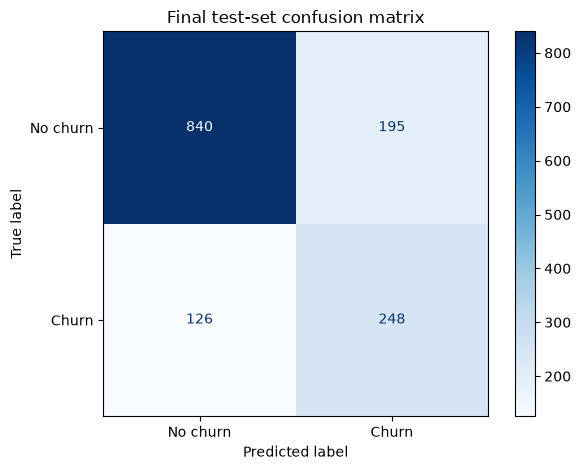

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["No churn", "Churn"], cmap="Blues"
)
plt.title("Final test-set confusion matrix")
plt.tight_layout()
plt.show()

## 16. Hypothesis review

Use your executed outputs to complete the table. A hypothesis should not be marked “supported” merely because the result seems plausible; cite the metric comparison that supports your conclusion.

In [15]:
hypothesis_review = pd.DataFrame([
    {"Hypothesis": "H1: Class weighting changes churn-class performance",
     "Evidence to report": "Compare baseline and class-weighted precision, recall, F1 and PR-AUC",
     "Conclusion": "Complete after reviewing results"},
    {"Hypothesis": "H2: Threshold changes precision and recall",
     "Evidence to report": "Use threshold_results table and plot",
     "Conclusion": "Complete after reviewing results"},
    {"Hypothesis": "H3: Highest accuracy may differ from best churn detection",
     "Evidence to report": "Compare validation accuracy and churn recall across models",
     "Conclusion": "Complete after reviewing results"}
])
display(hypothesis_review)

,Hypothesis,Evidence to report,Conclusion
0,H1: Class weighting changes churn-class perfor...,"Compare baseline and class-weighted precision,...",Complete after reviewing results
1,H2: Threshold changes precision and recall,Use threshold_results table and plot,Complete after reviewing results
2,H3: Highest accuracy may differ from best chur...,Compare validation accuracy and churn recall a...,Complete after reviewing results


## 17. Discussion and limitations

**Limitations:** 
- Results depend on the dataset, preprocessing, model settings, and
  random split.
- Class weighting can improve recall while increasing false positives
  and reducing precision.
- The threshold selected on validation data may not be optimal for a
  future population.
- The dataset may not represent every company's customers or churn
  behaviour.
- Further work could test additional datasets and estimate the
  business cost of false positives and false negatives.

## 18. Conclusion template


In this study, selected machine-learning models were evaluated for customer churn prediction using a stratified train/validation/test procedure. The best validation candidate was **Logistic Regression** under **Re-call**. Class weighting **did** improve churn recall, while threshold adjustment changed the precision–recall trade-off. On the held-out test set, the selected model achieved **77.2% accuracy, 56.0% churn precision, 66.3% churn recall, and an F1-score of 0.607**. The results suggest **class weighting and decision-threshold optimization can improve churn detection and help balance the identification of at-risk customers against false alarms**, subject to the limitations of the dataset and experimental design.


## 19. References to complete
**EDA & Preprocessing:** https://www.kaggle.com/code/yiitetinakmak/telco-customer-churn-part-1-eda-preprocessing/notebook

**MLPClassifier neural network:** https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

**Handling class Imbalance:** https://www.geeksforgeeks.org/machine-learning/handling-imbalanced-data-for-classification/

**Threashold Optimisation:** Lipton, Z. C., Elkan, C., & Naryanaswamy, B. (2014). Optimal Thresholding of Classifiers to Maximize F1 Measure. ECML-PKDD 2014, 225–239.

**Future work**
- Further work could test additional datasets, evaluate ROC curves and ROC-AUC as future analysis, and estimate the business cost of false positives and false negatives.
- Detailed Analytics of Dataset such as Dashboards for better visualizations



